# Wet vs. dry days and car crashes

We compare daily crash counts in Prince George’s County from 2019–2023.

A wet day has at least 0.04 inches of average precipitation across
reporting stations. We chose this cutoff before testing. Days below
this cutoff are labeled dry/low precipitation.

**Null hypothesis:** Both groups have the same mean daily crash count.

**Alternative hypothesis:** The mean daily crash counts differ.

We use a two-sided Welch’s t-test with a significance level of 0.05.
This test allows the groups to have different variances.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

url = "https://raw.githubusercontent.com/alex-sviriduk/maryland-precipitation-crashes/yuan-yin/precipitation-crash-correlation/prince_georges_precipitation_crash_analysis/pg_daily_precipitation_crashes_2019_2023.csv"
daily = pd.read_csv(url)
daily["date"]= pd.to_datetime(daily["date"])
daily.head()

,date,precipitation_mean_inches,precipitation_max_inches,share_stations_wet,n_stations,crashes
0,2019-01-01,0.514167,0.69,1.000000,12,65
1,2019-01-02,0.001538,0.01,0.153846,13,39
2,2019-01-03,0.004167,0.02,0.333333,12,35
3,2019-01-04,0.000000,0.00,0.000000,11,53
4,2019-01-05,0.070000,0.14,1.000000,12,58


In [2]:
print("Rows:", len(daily))
print("First date:", daily["date"].min())
print("Last date:", daily["date"].max())
print("Duplicate dates:",daily["date"].duplicated().sum())

print("Missing values:")
print(daily[["date", "precipitation_mean_inches", "crashes"]].isna().sum())

Rows: 1826
First date: 2019-01-01 00:00:00
Last date: 2023-12-31 00:00:00
Duplicate dates: 0
Missing values:
date                         0
precipitation_mean_inches    0
crashes                      0
dtype: int64


In [3]:
#splitting the daily crash counts into two groups.
wet = daily[daily["precipitation_mean_inches"] >= 0.04]["crashes"]
dry = daily[daily["precipitation_mean_inches"] < 0.04]["crashes"]

print("Wet days:", len(wet))
print("Wet mean:", round(wet.mean(), 2))
print("Wet standard deviation:", round(wet.std(), 2))
print()
print("Dry / low-precipitation days:", len(dry))
print("Dry mean:", round(dry.mean(), 2))
print("Dry standard deviation:", round(dry.std(), 2))

Wet days: 569
Wet mean: 55.3
Wet standard deviation: 12.4

Dry / low-precipitation days: 1257
Dry mean: 53.07
Dry standard deviation: 11.65


In [4]:
#equal_var=False makes this Welch's t-test.
result= stats.ttest_ind(wet, dry, equal_var=False, alternative="two-sided")
difference = wet.mean() - dry.mean()
interval= result.confidence_interval()

print("Mean difference:", round(difference, 2))
print("t-statistic:", round(result.statistic, 3))
print("p-value:", round(result.pvalue, 6))
print("95% confidence interval:",round(interval.low, 2), "to", round(interval.high, 2))

Mean difference: 2.24
t-statistic: 3.639
p-value: 0.000287
95% confidence interval: 1.03 to 3.44


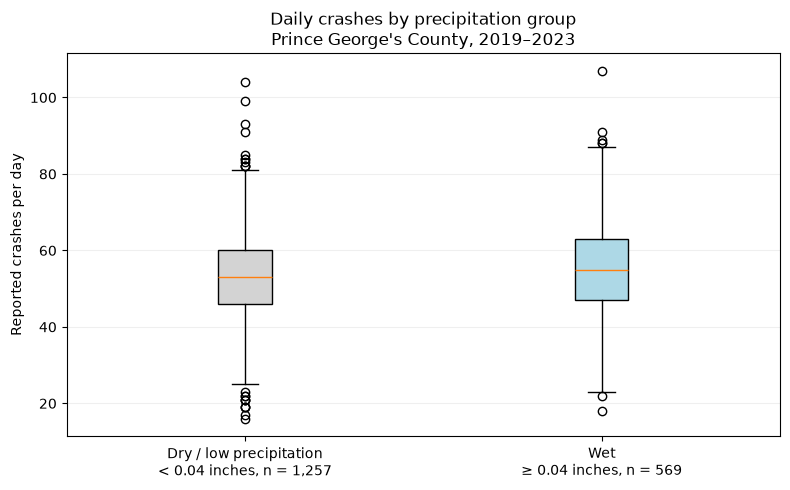

In [5]:
plt.figure(figsize=(8, 5))
boxes = plt.boxplot([dry, wet], patch_artist=True)
boxes["boxes"][0].set_facecolor("lightgray")
boxes["boxes"][1].set_facecolor("lightblue")

plt.xticks([1, 2],["Dry / low precipitation\n< 0.04 inches, n = 1,257", "Wet\n≥ 0.04 inches, n = 569"])
plt.ylabel("Reported crashes per day")
plt.title("Daily crashes by precipitation group\nPrince George's County, 2019–2023")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.savefig("wet_vs_dry_crashes.png",dpi=300)
plt.show()

## Results

The boxplot compares daily crash counts in the two groups.
The boxes show the middle 50% of values, and the lines inside show
the medians.

The 569 wet days averaged 55.30 crashes, while the 1,257 dry/low
precipitation days averaged 53.07. The difference, calculated before
rounding, was 2.24 crashes per day, with a 95% confidence interval
of 1.03–3.44.

Welch’s test gave t =3.639 and p = 0.000287. Since p < 0.05,
we reject the null hypothesis under the test’s assumptions.
Wet days had a higher average crash count, although the groups
overlap considerably.

## Limitations

The test assumes independent observations, but nearby days may be
related. We also did not adjust for season, weekday, or pandemic era
travel changes, so the p-value and confidence interval need caution.

Station averages approximate county weather, and the result depends
on our wet-day cutoff. Without traffic-volume data, this comparison
does not measure risk per trip or show that rain causes crashes.